# Docs figures: diurnal NEP, GPP and RECO by air temperature (LI-7200 years)

**notebook version**: `1` (19 Nov 2026)

## ℹ️ About this notebook

Draws the diurnal course of the net ecosystem production (`NEP`, the negative of `NEE`) of the
LI-7200 years and of its two parts, gross primary production (`GPP`) and ecosystem respiration
(`RECO`) from both partitioning methods, by class of air temperature, for June to September, and writes it to
`docs/images/NEP_IRGA72_diurnal_by_TA.png`. The figure is not yet shown on a documentation page.

Each curve is the mean `NEP` of the half-hours of one air-temperature class, per hour of the day.
The classes are taken from the air temperature of the same half-hour, so a class collects the
hours of many days, not whole days. `NEP` is the above-canopy flux of the whole ecosystem, including
the respiration of the soil and the understory; it is not the uptake of the trees alone.

**Data used** (external data folder):

- `30_FLUX_POST-PROCESSING_CHAIN/IRGA72/05_FPPC_IRGA72_NEE_2016-2026.09`:
  `NEE_L3.1_L3.3_CUT_50_QCF_gfXG`, the gap-filled `NEE` at the median USTAR threshold, and
  `GPP_NT_OF_CUT_50` and `RECO_NT_OF_CUT_50`, its night-time partitioning,
  `GPP_DT_OF_CUT_50` and `RECO_DT_OF_CUT_50`, its daytime partitioning, and
  `TA_T1_47_1_HOMOGENIZED_MEASURED`, the air temperature at 47 m

Run it after `IRGA72/05`. The figure is saved as a page would show it; the caption below it in this
notebook is added afterwards and is not part of the file.

## ⚙️ Settings

In [1]:
from pathlib import Path

ROOT = Path.cwd().resolve().parents[1]  # the repository root, two levels above this notebook
OUT = ROOT / 'docs' / 'images'
FIGNAME = 'NEP_IRGA72_diurnal_by_TA.png'
DATADIR = Path(r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow")
SOURCEFILE = DATADIR / '30_FLUX_POST-PROCESSING_CHAIN' / 'IRGA72' / '05_FPPC_IRGA72_NEE_2016-2026.09.parquet'
NEE = 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG'
TA = 'TA_T1_47_1_HOMOGENIZED_MEASURED'
# Night-time partitioning: GPP_NT = RECO_NT - NEE holds for every half-hour, so the three panels
# add up. RECO_NT is a temperature model fitted on night-time NEE.
GPP, RECO = 'GPP_NT_OF_CUT_50', 'RECO_NT_OF_CUT_50'
# Daytime partitioning, from light-response fits; it does not add up to NEE exactly.
GPP_DT, RECO_DT = 'GPP_DT_OF_CUT_50', 'RECO_DT_OF_CUT_50'
# For the check of the respiration model at daytime temperatures: the measured NEE the night-time
# model is fitted on, the day/night flag, and the fitted temperature sensitivity E0 (K)
NEE_MEAS, DAYTIME = 'NEE_L3.1_L3.3_CUT_50_QCF', 'DAYTIME'
E0_NT, E0_DT = 'E0_NT_OF_CUT_50', 'E0_DT_OF_CUT_50'
RREF_NT, RREF_DT = 'RREF_NT_OF_CUT_50', 'RREF_DT_OF_CUT_50'   # respiration at 15 degC, umol m-2 s-1
WINDOW_DAYS = 15                            # nights within +-7 days of a daytime half-hour

MONTHS = [6, 7, 8, 9]                       # June to September
EDGES = [4, 8, 12, 16, 20, 24, 28, 50]      # class limits of the air temperature, degC
LABELS = ['6 °C', '10 °C', '14 °C', '18 °C', '22 °C', '26 °C', '≥ 28 °C']
HOURS = (6, 20)                             # hours of the day shown
MIN_N = 20                                  # half-hours a class needs in an hour to be drawn
UMOL_TO_G_CO2_PER_H = 44.01e-6 * 3600       # umol CO2 m-2 s-1 -> g CO2 m-2 h-1

INK, MUTED, GRID = '#1F2623', '#5A6460', '#E4E7E4'
UPTAKE_BG, RELEASE_BG = '#EEF6EC', '#FAEEEC'
COLORS = ['#2B1D5C', '#3A7FD0', '#3CC98A', '#D6C92B', '#E8701C', '#B8281B', '#4A0A07']

In [2]:
from datetime import datetime
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({'font.size': 10, 'axes.edgecolor': MUTED, 'axes.labelcolor': INK,
                     'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.spines.top': False,
                     'axes.spines.right': False, 'savefig.dpi': 150, 'figure.dpi': 100})

def figcap(fig, text, width=150):
    """Place a caption under a figure drawn with a layout engine. Call after the last axes."""
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    fig.supxlabel(textwrap.fill(f"Figure - {text}", width), fontsize=9, ha='left', x=0.005)


def save_for_docs(fig, name):
    """Write the figure as the docs page shows it, before the notebook caption is added."""
    path = OUT / name
    fig.savefig(path)
    print(f"written: {path.relative_to(ROOT)}")
    return path


NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")

Last run: 2026-11-19 17:41:49


## 📂 Load data

In [3]:
if not SOURCEFILE.exists():
    raise FileNotFoundError(f"{SOURCEFILE} is missing: this notebook needs the external data folder "
                            "and the output of IRGA72/05.")
df = pd.read_parquet(SOURCEFILE, columns=[NEE, GPP, RECO, GPP_DT, RECO_DT, TA, NEE_MEAS, DAYTIME,
                                          E0_NT, E0_DT, RREF_NT, RREF_DT]).replace(-9999, np.nan)
df.index = pd.DatetimeIndex(df.index)
assert not df.index.duplicated().any(), "duplicate timestamps"
print(f"{SOURCEFILE.name}: {df.index[0]} -> {df.index[-1]}")

d = df[df.index.month.isin(MONTHS)].copy()
assert d[[NEE, GPP, RECO, GPP_DT, RECO_DT]].notna().all().all(), "NEE, GPP or RECO has gaps in June to September"
_closure = (d[NEE] - (d[RECO] - d[GPP])).abs().max()
print(f"largest |NEE - (RECO - GPP)|: {_closure:.1e} umol m-2 s-1")
assert _closure < 1e-3, "NEE, GPP and RECO do not add up"
d['NEP'] = -d[NEE] * UMOL_TO_G_CO2_PER_H
d['GPP_NT'] = d[GPP] * UMOL_TO_G_CO2_PER_H
d['RECO_NT'] = d[RECO] * UMOL_TO_G_CO2_PER_H
d['GPP_DT'] = d[GPP_DT] * UMOL_TO_G_CO2_PER_H
d['RECO_DT'] = d[RECO_DT] * UMOL_TO_G_CO2_PER_H
d['CLASS'] = pd.cut(d[TA], EDGES, labels=LABELS, right=False)
d['HOUR'] = d.index.hour + 0.5             # the half-hours :15 and :45 give the hourly mean at :30
# Respiration at daytime temperatures: is a daytime half-hour warmer than every night with measured
# NEE (the records the night-time model is fitted on) within +-7 days?
_fit_nights = d[(d[DAYTIME] == 0) & d[NEE_MEAS].notna()][TA]
_warmest = _fit_nights.resample('D').max().rolling(WINDOW_DAYS, center=True, min_periods=1).max()
d['WARMEST_NIGHT'] = _warmest.reindex(d.index.normalize()).values
d['ABOVE_NIGHTS'] = (d[DAYTIME] == 1) & (d[TA] > d['WARMEST_NIGHT'])
print(f"June to September: {len(d):,} half-hours, {d[TA].isna().sum():,} without air temperature, "
      f"{(d[TA] < EDGES[0]).sum():,} below {EDGES[0]} degC; both are left out")
dall = d.copy()                            # all hours of June to September, for the night checks
d = d.dropna(subset=['CLASS'])
d = d[(d['HOUR'] > HOURS[0] - 1) & (d['HOUR'] < HOURS[1] + 1)]

05_FPPC_IRGA72_NEE_2016-2026.09.parquet: 2016-01-01 00:15:00 -> 2026-09-30 23:45:00
largest |NEE - (RECO - GPP)|: 3.8e-06 umol m-2 s-1
June to September: 64,416 half-hours, 100 without air temperature, 0 below 4 degC; both are left out


## Diurnal NEP, GPP and RECO by air temperature

In [4]:
FLUXES = ['NEP', 'GPP_NT', 'RECO_NT', 'GPP_DT', 'RECO_DT']
g = d.groupby(['CLASS', 'HOUR'], observed=True)[FLUXES].mean()
n = d.groupby(['CLASS', 'HOUR'], observed=True).size()
g = g[n >= MIN_N].reset_index()
ALL_HOURS = np.arange(HOURS[0] - 0.5, HOURS[1] + 1)
mid = d[(d['HOUR'] > 11) & (d['HOUR'] < 14)]      # 11:00-14:00, for the caption and the table
MID = mid.groupby('CLASS', observed=True)[FLUXES].mean()
_day = d[d[DAYTIME] == 1]
EXTRAP = _day.groupby('CLASS', observed=True)['ABOVE_NIGHTS'].mean()   # share per class

### 📊 Plot: diurnal NEP, GPP and RECO by class of air temperature, both partitioning methods

written: docs\images\NEP_IRGA72_diurnal_by_TA.png


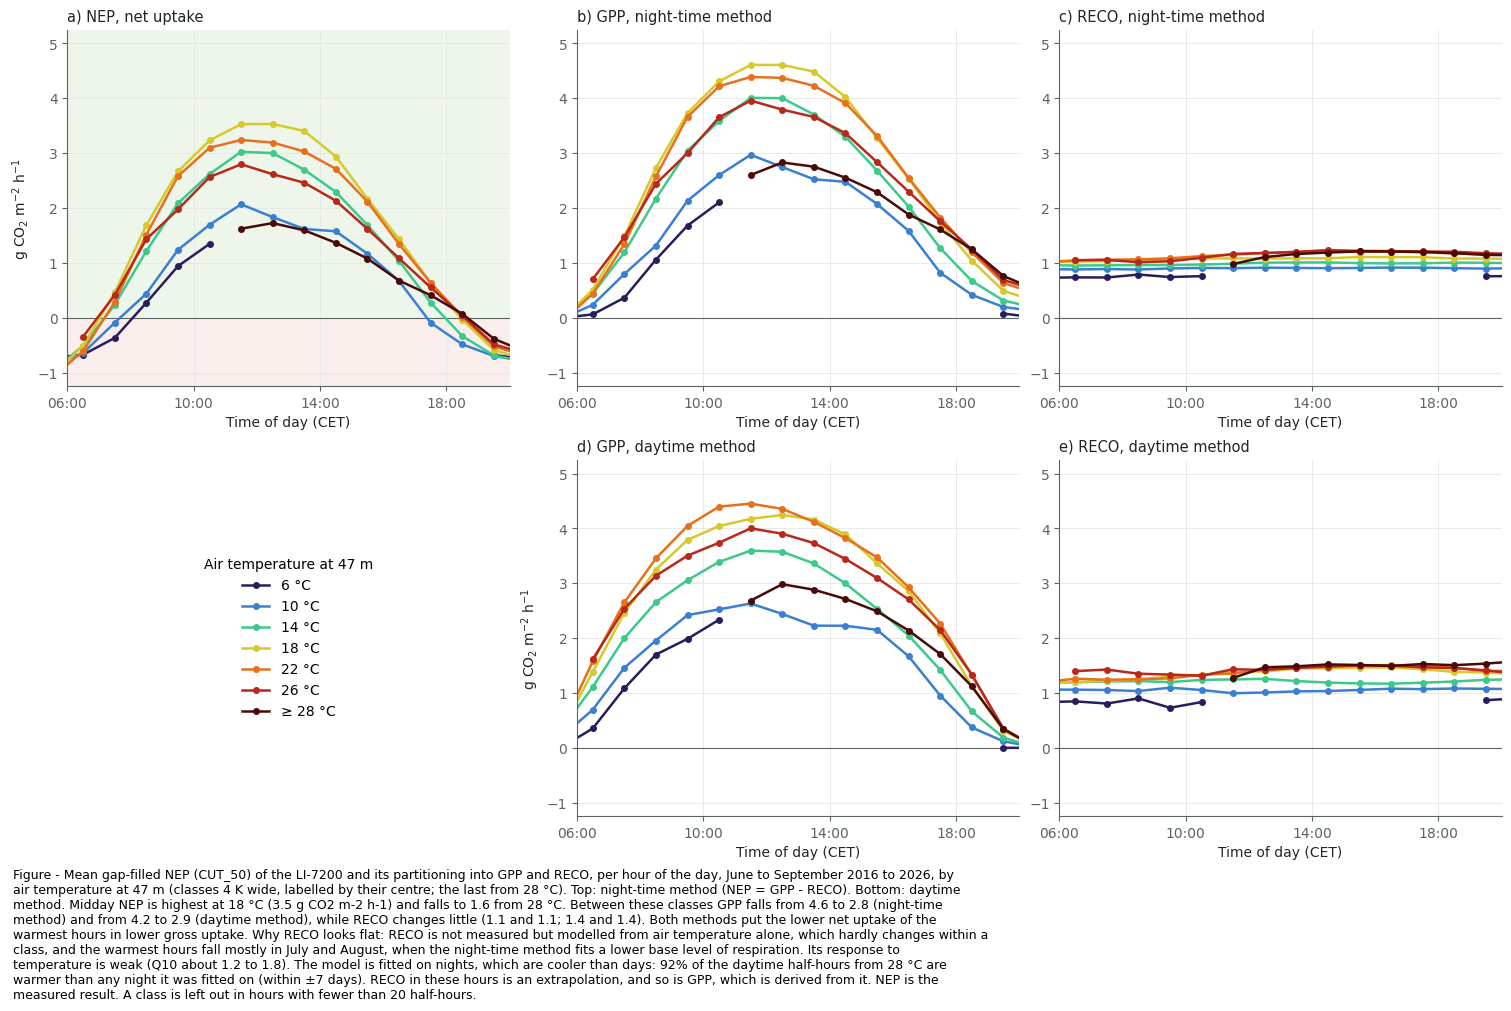

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10), layout='constrained')  # same limits set below
_shown = g[(g['HOUR'] > HOURS[0]) & (g['HOUR'] < HOURS[1])][FLUXES]
ymin = np.floor(_shown.min().min() * 2) / 2 - 0.25
ymax = np.ceil(_shown.max().max() * 2) / 2 + 0.25
PANELS = {(0, 0): ('NEP', 'a) NEP, net uptake'),
          (0, 1): ('GPP_NT', 'b) GPP, night-time method'),
          (0, 2): ('RECO_NT', 'c) RECO, night-time method'),
          (1, 1): ('GPP_DT', 'd) GPP, daytime method'),
          (1, 2): ('RECO_DT', 'e) RECO, daytime method')}
for (r, c), (flux, title) in PANELS.items():
    ax = axes[r, c]
    if flux == 'NEP':
        ax.axhspan(0, ymax, color=UPTAKE_BG, lw=0, zorder=0)
        ax.axhspan(ymin, 0, color=RELEASE_BG, lw=0, zorder=0)
    ax.axhline(0, color=MUTED, lw=0.8)
    for label, color in zip(LABELS, COLORS):
        # hours with too few half-hours stay empty, so the line breaks there instead of bridging them
        s = g[g['CLASS'] == label].set_index('HOUR')[flux].reindex(ALL_HOURS)
        ax.plot(s.index, s.values, '-o', color=color, lw=1.8, ms=4, label=label)
    ax.grid(color=GRID, lw=0.6)
    ax.set_title(title, loc='left', fontsize=10.5, color=INK)
for ax in axes.flat:
    ax.set_xlim(*HOURS)
    ax.set_ylim(ymin, ymax)
    ax.set_xticks(range(HOURS[0], HOURS[1] + 1, 4))
    ax.set_xticklabels([f'{h:02d}:00' for h in range(HOURS[0], HOURS[1] + 1, 4)])
for r, c in PANELS:
    axes[r, c].set_xlabel('Time of day (CET)')
for ax in (axes[0, 0], axes[1, 1]):
    ax.set_ylabel('g CO$_2$ m$^{-2}$ h$^{-1}$')
# The free panel holds the legend
axes[1, 0].axis('off')
axes[1, 0].legend(*axes[0, 0].get_legend_handles_labels(), title='Air temperature at 47 m',
                  loc='center', fontsize=10, title_fontsize=10, frameon=False)
save_for_docs(fig, FIGNAME)
_best = MID['NEP'].idxmax()
_hot = '≥ 28 °C'
# The caption says that RECO changes little and the drop of NEP comes from GPP, with both methods.
for _m in ('NT', 'DT'):
    _d_reco = MID.loc[_hot, f'RECO_{_m}'] - MID.loc[_best, f'RECO_{_m}']
    _d_gpp = MID.loc[_hot, f'GPP_{_m}'] - MID.loc[_best, f'GPP_{_m}']
    assert abs(_d_reco) < 0.3 and abs(_d_gpp) > 3 * abs(_d_reco), f"caption wording no longer fits ({_m})"
figcap(fig, f"Mean gap-filled NEP (CUT_50) of the LI-7200 and its partitioning into GPP and RECO, per "
            f"hour of the day, June to September {d.index.year.min()} to {d.index.year.max()}, by air "
            f"temperature at 47 m (classes 4 K wide, labelled by their centre; the last from 28 °C). "
            f"Top: night-time method (NEP = GPP - RECO). Bottom: daytime method. Midday NEP is highest at "
            f"{_best} ({MID.loc[_best, 'NEP']:.1f} g CO2 m-2 h-1) and falls to {MID.loc[_hot, 'NEP']:.1f} "
            f"from 28 °C. Between these classes GPP falls from {MID.loc[_best, 'GPP_NT']:.1f} to "
            f"{MID.loc[_hot, 'GPP_NT']:.1f} (night-time method) and from {MID.loc[_best, 'GPP_DT']:.1f} to "
            f"{MID.loc[_hot, 'GPP_DT']:.1f} (daytime method), while RECO changes little "
            f"({MID.loc[_best, 'RECO_NT']:.1f} and {MID.loc[_hot, 'RECO_NT']:.1f}; "
            f"{MID.loc[_best, 'RECO_DT']:.1f} and {MID.loc[_hot, 'RECO_DT']:.1f}). Both methods put the "
            f"lower net uptake of the warmest hours in lower gross uptake. "
            f"Why RECO looks flat: RECO is not measured but modelled from air temperature alone, which "
            f"hardly changes within a class, and the warmest hours fall mostly in July and August, when "
            f"the night-time method fits a lower base level of respiration. Its response to temperature is "
            f"weak (Q10 about 1.2 to 1.8). The model is fitted on nights, which are cooler than "
            f"days: {EXTRAP[_hot]:.0%} of the daytime half-hours from 28 °C are warmer than any night it "
            f"was fitted on (within ±7 days). RECO in these hours is an extrapolation, and so is GPP, "
            f"which is derived from it. NEP is the measured result. A class is left out in hours with "
            f"fewer than {MIN_N} half-hours.")
plt.show()

### 📋 Table: midday NEP, GPP and RECO and number of half-hours per class

In [6]:
t = MID.rename(columns=lambda c: f'{c} 11:00-14:00 (g CO2 m-2 h-1)')
t['half-hours 11:00-14:00'] = mid.groupby('CLASS', observed=True).size()
t['days'] = mid.groupby('CLASS', observed=True).apply(lambda x: x.index.normalize().nunique())
display(t.round(2).style.set_caption("Table - mean NEP, GPP and RECO of both partitioning methods "
                                     "between 11:00 and 14:00 (CET) per class of air temperature, "
                                     "June to September, and the number of half-hours and days they "
                                     "rest on"))

,NEP 11:00-14:00 (g CO2 m-2 h-1),GPP_NT 11:00-14:00 (g CO2 m-2 h-1),RECO_NT 11:00-14:00 (g CO2 m-2 h-1),GPP_DT 11:00-14:00 (g CO2 m-2 h-1),RECO_DT 11:00-14:00 (g CO2 m-2 h-1),half-hours 11:00-14:00,days
CLASS,,,,,,,
6 °C,1.340000,2.110000,0.770000,1.990000,0.730000,44,12
10 °C,1.860000,2.770000,0.910000,2.460000,1.010000,453,112
14 °C,2.920000,3.920000,1.000000,3.520000,1.240000,1343,347
18 °C,3.490000,4.570000,1.080000,4.190000,1.410000,2184,562
22 °C,3.150000,4.330000,1.180000,4.310000,1.410000,2332,597
26 °C,2.600000,3.780000,1.180000,3.860000,1.440000,1315,356
≥ 28 °C,1.640000,2.760000,1.110000,2.890000,1.450000,363,102


## Respiration at daytime temperatures

Both partitioning methods take the response of respiration to air temperature from the nights and
apply it to the daytime air temperature. The two tables show how far the daytime temperatures lie
beyond the nights the model is fitted on, what the measured nights show, and how strong the fitted
temperature response is.

### 📋 Table: daytime half-hours warmer than the fitted nights, and measured night NEE, per class

In [7]:
_nights = dall[(dall[DAYTIME] == 0) & dall[NEE_MEAS].notna()]
t2 = pd.DataFrame({
    'daytime half-hours warmer than any fitted night within ±7 days (%)': (EXTRAP * 100).round(0),
    'measured night NEE (umol m-2 s-1)': _nights.groupby('CLASS', observed=True)[NEE_MEAS].mean().round(2),
    'measured night half-hours': _nights.groupby('CLASS', observed=True).size(),
})
display(t2.style.format(precision=2).set_caption(
    "Table - per class of air temperature, June to September: share of the daytime half-hours that "
    "are warmer than every night with measured NEE within ±7 days, and the mean measured NEE of the "
    "nights of the class"))

,daytime half-hours warmer than any fitted night within ±7 days (%),measured night NEE (umol m-2 s-1),measured night half-hours
CLASS,,,
6 °C,0.00,4.93,116
10 °C,1.00,5.54,680
14 °C,1.00,6.65,1485
18 °C,6.00,6.90,1509
22 °C,25.00,5.99,805
26 °C,52.00,5.24,241
≥ 28 °C,92.00,4.27,20


### 📋 Table: fitted temperature sensitivity of respiration per year

In [8]:
def q10(e0, t1=10.0, t2=20.0):
    """Q10 between t1 and t2 (degC) of a Lloyd-Taylor curve with the activation parameter e0 (K)."""
    return np.exp(e0 * (1 / (t1 + 46.02) - 1 / (t2 + 46.02)))


e0 = dall.groupby(dall.index.year)[[E0_NT, E0_DT]].median()
assert e0.notna().all().all(), "E0 is missing for a year"
e0['Q10 night-time method'] = q10(e0[E0_NT])
e0['Q10 daytime method'] = q10(e0[E0_DT])
display(e0.round(2).style.format(precision=2).set_caption(
    "Table - temperature sensitivity E0 (K) of the respiration model, June to September median per "
    "year, and the Q10 between 10 and 20 °C it implies"))

,E0_NT_OF_CUT_50,E0_DT_OF_CUT_50,Q10 night-time method,Q10 daytime method
TIMESTAMP_MIDDLE,,,,
2016,105.04,187.66,1.33,1.66
2017,97.74,178.27,1.30,1.62
2018,175.14,130.28,1.61,1.42
2019,111.96,214.57,1.35,1.79
2020,132.87,128.39,1.43,1.42
2021,143.65,101.70,1.47,1.32
2022,137.85,167.07,1.45,1.57
2023,151.44,120.10,1.51,1.38
2024,124.85,166.33,1.40,1.57


### 📋 Table: base respiration and share of the warm hours per month

In [9]:
_months = dall.groupby(dall.index.month)
t3 = pd.DataFrame({'Rref night-time method (umol m-2 s-1)': _months[RREF_NT].median(),
                   'Rref daytime method (umol m-2 s-1)': _months[RREF_DT].median()})
_warm = dall[dall[TA] >= 24]
t3['share of the half-hours from 24 °C (%)'] = (_warm.groupby(_warm.index.month).size()
                                                 / len(_warm) * 100).round(0)
t3.index.name = 'month'
display(t3.style.format(precision=2).set_caption(
    "Table - base respiration Rref (respiration at 15 °C) per month, median over the years, and "
    "how the half-hours from 24 °C are spread over the months"))

,Rref night-time method (umol m-2 s-1),Rref daytime method (umol m-2 s-1),share of the half-hours from 24 °C (%)
month,,,
6,6.45,6.97,24.00
7,5.72,7.34,32.00
8,5.54,6.84,37.00
9,5.81,6.56,7.00


## ⏱️ Runtime

In [10]:
print(f"Finished: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}, "
      f"runtime {datetime.now() - NOTEBOOK_START}")

Finished: 2026-11-19 17:41:51, runtime 0:00:01.609110
